In [1]:
!pip -q install pypdf

In [2]:
from pathlib import Path
from pypdf import PdfReader

pdf = next(Path("/kaggle/input").rglob("DS plan.pdf"))
reader = PdfReader(pdf)

print("Pages:", len(reader.pages))
print(reader.pages[0].extract_text())

Pages: 16
viewplan
B.Sc of Data science -
 Show All  Hide All
University Compulsory Req. (16) Hours:
Line No. Code Course Hours Prerequisite TeachingMethod  
801022 ARB102 communication skills in arabic 3 --- Blended
 Syllabus
Course
Description
Course
Evaluation
821007 HSS100CY fundamentals of cybersecurity and ai 2 --- ElectronicCourse
 Syllabus
Course
Description
Course
Evaluation
821106 HSS110 national education 2 --- ElectronicCourse
 Syllabus
Course
Description
Course
Evaluation
821200 HSS120 entrepreneurship, innovation & life skills 3 --- ElectronicCourse
 Syllabus
Course
Description
Course
Evaluation
841000 MS100 military sciences 3 --- Blended
 Syllabus
Course
Description
Course
Evaluation
2511010 LG101 communication skills in english 3 Blended
 Syllabus
Course
Description
Course
Evaluation
2510990 LG099 english language (remedial course) 3 Prerequisite /Pass Blended
 Syllabus
Course
Description
Course
Evaluation
2511120 LG112 english language (2) 3 Equivalent Blended
 Syllab

In [3]:
folder = Path("/kaggle/working/raw_pages")
folder.mkdir(exist_ok=True)

for number, page in enumerate(reader.pages, start=1):
    text = page.extract_text() or ""
    file = folder / f"page_{number:02d}.txt"
    file.write_text(text, encoding="utf-8")
    print(f"Page {number}: {len(text)} characters")

Page 1: 1165 characters
Page 2: 1548 characters
Page 3: 1250 characters
Page 4: 1191 characters
Page 5: 1667 characters
Page 6: 1642 characters
Page 7: 1470 characters
Page 8: 1277 characters
Page 9: 1223 characters
Page 10: 1260 characters
Page 11: 1314 characters
Page 12: 1308 characters
Page 13: 1167 characters
Page 14: 1275 characters
Page 15: 1257 characters
Page 16: 43 characters


In [4]:
import re

raw_folder = Path("/kaggle/working/raw_pages")
clean_folder = Path("/kaggle/working/clean_pages")
clean_folder.mkdir(exist_ok=True)

for file in sorted(raw_folder.glob("page_*.txt")):
    text = file.read_text(encoding="utf-8")

    text = re.sub(
        r"\b(Syllabus|Course\s+Description|Course\s+Evaluation)\b",
        "",
        text,
        flags=re.IGNORECASE
    )

    lines = []
    for line in text.splitlines():
        line = line.strip()
        if line and not line.startswith("about:blank"):
            lines.append(line)

    cleaned = "\n".join(lines)
    (clean_folder / file.name).write_text(cleaned, encoding="utf-8")

print("First page after cleaning:\n")
print((clean_folder / "page_01.txt").read_text(encoding="utf-8"))

First page after cleaning:

viewplan
B.Sc of Data science -
Show All  Hide All
University Compulsory Req. (16) Hours:
Line No. Code Course Hours Prerequisite TeachingMethod
801022 ARB102 communication skills in arabic 3 --- Blended
821007 HSS100CY fundamentals of cybersecurity and ai 2 --- ElectronicCourse
821106 HSS110 national education 2 --- ElectronicCourse
821200 HSS120 entrepreneurship, innovation & life skills 3 --- ElectronicCourse
841000 MS100 military sciences 3 --- Blended
2511010 LG101 communication skills in english 3 Blended
2510990 LG099 english language (remedial course) 3 Prerequisite /Pass Blended
2511120 LG112 english language (2) 3 Equivalent Blended
University Elective Req. (9) Hours:
Line No. Code Course Hours Prerequisite TeachingMethod
11/11/26, 12:41 AM my div


In [5]:
(clean_folder / "page_16.txt").unlink(missing_ok=True)

for file in clean_folder.glob("*.txt"):
    text = file.read_text(encoding="utf-8")
    text = re.sub(r"(?m)^\d+/\d+/\d+,.*$", "", text)
    text = re.sub(r"\n\s*\n", "\n", text)
    file.write_text(text.strip(), encoding="utf-8")

print("Cleaned pages:", len(list(clean_folder.glob("*.txt"))))

Cleaned pages: 15


In [6]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("gpt2")

total = 0
for file in sorted(clean_folder.glob("*.txt")):
    text = file.read_text(encoding="utf-8")
    count = len(tokenizer.encode(text))
    total += count
    print(file.name, count)

print("Total tokens:", total)
print("10% target:", round(total * 0.10))

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

page_01.txt 191
page_02.txt 249
page_03.txt 175
page_04.txt 163
page_05.txt 252
page_06.txt 246
page_07.txt 214
page_08.txt 179
page_09.txt 187
page_10.txt 200
page_11.txt 196
page_12.txt 182
page_13.txt 162
page_14.txt 175
page_15.txt 178
Total tokens: 2949
10% target: 295


In [7]:
import json

train_pages = []
validation_pages = ["page_05.txt"]

for file in sorted(clean_folder.glob("*.txt")):
    if file.name not in validation_pages:
        train_pages.append(file.name)

split = {
    "train": train_pages,
    "validation": validation_pages
}

Path("/kaggle/working/split.json").write_text(
    json.dumps(split, indent=2),
    encoding="utf-8"
)

print("Training pages:", len(train_pages))
print("Validation pages:", validation_pages)

Training pages: 14
Validation pages: ['page_05.txt']


In [8]:
!nvidia-smi

Mon Nov 16 18:24:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [9]:
import torch
from transformers import AutoModelForCausalLM

torch.manual_seed(42)

tokenizer = AutoTokenizer.from_pretrained("gpt2")
model = AutoModelForCausalLM.from_pretrained("gpt2").to("cuda")
model.eval()

print("GPT-2 is ready")

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT-2 is ready


In [10]:
import math

text = Path("/kaggle/working/clean_pages/page_05.txt").read_text(
    encoding="utf-8"
)
inputs = tokenizer(text, return_tensors="pt").to("cuda")

model.eval()
with torch.no_grad():
    loss = model(**inputs, labels=inputs["input_ids"]).loss.item()

result = {
    "model": "gpt2-base",
    "validation_page": 5,
    "tokens": inputs["input_ids"].shape[1],
    "loss": loss,
    "perplexity": math.exp(loss)
}

Path("/kaggle/working/base_metrics.json").write_text(
    json.dumps(result, indent=2),
    encoding="utf-8"
)

print("Base loss:", round(loss, 4))
print("Base perplexity:", round(result["perplexity"], 2))

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Base loss: 3.3097
Base perplexity: 27.38


In [11]:
prompts = [
    "The Data Science study plan",
    "University compulsory requirements",
    "The course Machine Learning",
    "Programming for Data Science",
    "Graduation project"
]

samples = []
model.eval()

for prompt in prompts:
    inputs = tokenizer(prompt, return_tensors="pt").to("cuda")

    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=40,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    completion = tokenizer.decode(output[0], skip_special_tokens=True)
    samples.append({"prompt": prompt, "completion": completion})
    print(completion, "\n")

Path("/kaggle/working/base_completions.json").write_text(
    json.dumps(samples, indent=2),
    encoding="utf-8"
)

The Data Science study plan is to use the data from the National Health and Nutrition Examination Survey (NHANES) to determine the prevalence of obesity among US adults.

The study will use data from the National Health and 

University compulsory requirements for the study of the history of the United States, and the history of the United States, are not applicable to the study of the history of the United States.

(b) The study 

The course Machine Learning is designed to teach you how to build a machine learning model that can be used to predict the future.

Machine Learning is a new field of research that has been gaining traction in the last few 

Programming for Data Science

The following is a list of the most popular programming languages for data science.

C#

C# is a programming language for data science. It is a programming language that is 

Graduation project.

The project is now complete.

The project is now complete.

The project is now complete.

The project is now comp

1420

In [12]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained("gpt2")
work = Path("/kaggle/working")

text = ""
for name in split["train"]:
    text += (clean_folder / name).read_text(encoding="utf-8") + "\n"

courses = []

for row in re.split(r"(?m)(?=^\d{5,}\s+[A-Za-z])", text):
    if not row.strip():
        continue

    if courses and re.search(
        r"\b\d+\s+(Prerequisite|Equivalent|Concurrent|Pre\./Con\.)",
        row
    ):
        courses[-1] += "\n" + row
    else:
        courses.append(row)

train_blocks = []

for course in courses:
    tokens = tokenizer.encode(course) + [tokenizer.eos_token_id]

    if len(tokens) > 512:
        raise ValueError("A course group exceeds 512 tokens and needs review.")

    train_blocks.append(tokens)

prepared = {
    "train_blocks": train_blocks,
    "validation_pages": split["validation"]
}

(work / "cpt_data.json").write_text(
    json.dumps(prepared, indent=2),
    encoding="utf-8"
)

print("Training blocks:", len(train_blocks))
print("First three groups:")

for course in courses[:3]:
    print("\n", course)

Training blocks: 92
First three groups:

 viewplan
B.Sc of Data science -
Show All  Hide All
University Compulsory Req. (16) Hours:
Line No. Code Course Hours Prerequisite TeachingMethod


 801022 ARB102 communication skills in arabic 3 --- Blended


 821007 HSS100CY fundamentals of cybersecurity and ai 2 --- ElectronicCourse



In [13]:
print("Total groups:", len(courses))

for number, group in enumerate(courses, start=1):
    if "Concurrent" in group or "Pre./Con." in group:
        print(f"\n--- Group {number} ---")
        print(group)

Total groups: 92

--- Group 60 ---
8210111 HSS101CS introduction to programming 3 OnCampus

1740990 CIs099 computer skills (remedial course) 3 Pre./Con. ElectronicCourse


--- Group 63 ---
821061 HSS106CS introduction to programming lab 1 OnCampus

8210111 HSS101CS introduction to programming 3 Concurrent OnCampus


--- Group 64 ---
821131 HSS113SE introduction to object- orientedprogramming lab 1 OnCampus

821127 HSS112SE introduction to object- orientedprogramming 3 Concurrent OnCampus


--- Group 65 ---
822123 HSS212CS data structures lab 1 OnCampus

822112 HSS211CS data structures 3 Pre./Con. OnCampus


--- Group 71 ---
1781020 DS102 fundamentals of data sciencelaboratory 1 OnCampus

1781011 DS101 fundamentals of data science andartificial intelligence 3 Concurrent OnCampus


--- Group 72 ---
1781101 DS110 programming for data science 3 OnCampus

1781011 DS101 fundamentals of data science andartificial intelligence 3 Prerequisite /Study OnCampus

1781020 DS102 fundamentals of data 

In [14]:
for course in courses:
    if "DS360" in course:
        print(course)

1783600 DS360 information security 3 Blended

1782301 DS230 machine learning 3 Prerequisite /Study OnCampus

2033410 HI341 information security and networkstechnology and policies 3 Equivalent OnCampus



In [15]:
from torch.utils.data import DataLoader

ids = torch.full((len(train_blocks), 512), tokenizer.eos_token_id)
mask = torch.zeros_like(ids)

for i, block in enumerate(train_blocks):
    ids[i, :len(block)] = torch.tensor(block)
    mask[i, :len(block)] = 1

labels = ids.clone()
labels[mask == 0] = -100

torch.manual_seed(42)
train_loader = DataLoader(
    list(zip(ids, mask, labels)), batch_size=4, shuffle=True
)

print("Batches:", len(train_loader))

Batches: 23


In [16]:
print("Tokenizer size:", len(tokenizer))
print("EOS token:", tokenizer.eos_token_id)
print("Highest CPT token:", max(max(block) for block in train_blocks))

Tokenizer size: 50257
EOS token: 50256
Highest CPT token: 50256


In [17]:
torch.manual_seed(42)

model = AutoModelForCausalLM.from_pretrained("gpt2").to("cuda")
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5)

history = []
best_loss = float("inf")
best_epoch = 0

text = (work / "clean_pages/page_05.txt").read_text(encoding="utf-8")
validation = tokenizer(text, return_tensors="pt").to("cuda")

for epoch in range(1, 6):
    model.train()
    losses = []

    for ids, mask, labels in train_loader:
        optimizer.zero_grad()

        loss = model(
            input_ids=ids.to("cuda"),
            attention_mask=mask.to("cuda"),
            labels=labels.to("cuda")
        ).loss

        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    model.eval()
    with torch.no_grad():
        val_loss = model(
            **validation,
            labels=validation["input_ids"]
        ).loss.item()

    perplexity = math.exp(val_loss)

    history.append({
        "epoch": epoch,
        "training_losses": losses,
        "validation_loss": val_loss,
        "perplexity": perplexity
    })

    checkpoint = work / f"cpt_epoch_{epoch}"
    model.save_pretrained(checkpoint)
    tokenizer.save_pretrained(checkpoint)

    (work / "cpt_history.json").write_text(
        json.dumps(history, indent=2)
    )

    print(f"\nEpoch {epoch}/5")
    print(f"Average training loss: {sum(losses) / len(losses):.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Validation perplexity: {perplexity:.2f}")

    if val_loss < best_loss:
        best_loss = val_loss
        best_epoch = epoch
        model.save_pretrained(work / "cpt_best")
        tokenizer.save_pretrained(work / "cpt_best")
    elif epoch >= 3:
        print("Stopped: validation loss stopped improving")
        break

print(f"\nBest epoch: {best_epoch}")
print(f"Best perplexity: {math.exp(best_loss):.2f}")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Epoch 1/5
Average training loss: 4.4489
Validation loss: 2.6236
Validation perplexity: 13.79


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Epoch 2/5
Average training loss: 2.5286
Validation loss: 2.3455
Validation perplexity: 10.44


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Epoch 3/5
Average training loss: 1.9286
Validation loss: 2.3682
Validation perplexity: 10.68
Stopped: validation loss stopped improving

Best epoch: 2
Best perplexity: 10.44


In [18]:
model = AutoModelForCausalLM.from_pretrained(
    work / "cpt_best"
).to("cuda")

model.eval()
print("Best CPT model loaded")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Best CPT model loaded


In [19]:
before = json.loads(
    (work / "base_completions.json").read_text()
)
after = []

model.eval()

for sample in before:
    prompt = sample["prompt"]
    inputs = tokenizer(prompt, return_tensors="pt").to("cuda")

    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=40,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    completion = tokenizer.decode(output[0], skip_special_tokens=True)
    after.append({"prompt": prompt, "completion": completion})

    print("BEFORE:", sample["completion"])
    print("AFTER:", completion)
    print()

(work / "cpt_completions.json").write_text(
    json.dumps(after, indent=2), encoding="utf-8"
)

BEFORE: The Data Science study plan is to use the data from the National Health and Nutrition Examination Survey (NHANES) to determine the prevalence of obesity among US adults.

The study will use data from the National Health and
AFTER: The Data Science study plan is available at http://www.cs.edu/programming/


BEFORE: University compulsory requirements for the study of the history of the United States, and the history of the United States, are not applicable to the study of the history of the United States.

(b) The study
AFTER: University compulsory requirements for the course

Course Hours

8:00 AM - 3:00 PM

Course Hours

8:00 AM - 3:00 PM


BEFORE: The course Machine Learning is designed to teach you how to build a machine learning model that can be used to predict the future.

Machine Learning is a new field of research that has been gaining traction in the last few
AFTER: The course Machine Learning and Data Science 3 OnCampus

82101 HSS211 machine learning and data science 3

1027

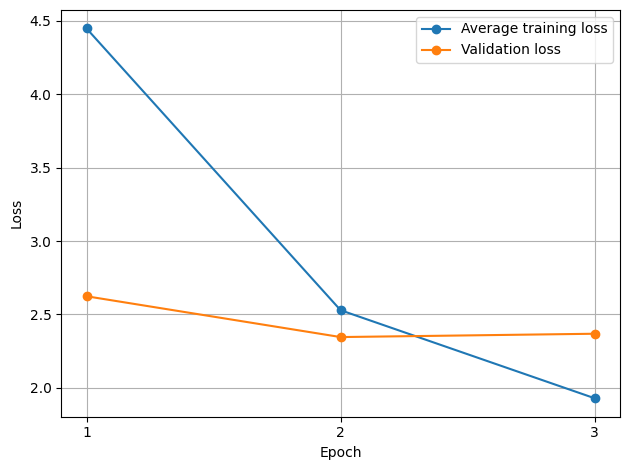

In [20]:
import matplotlib.pyplot as plt

history = json.loads((work / "cpt_history.json").read_text())

epochs = []
train_loss = []
validation_loss = []

for result in history:
    epochs.append(result["epoch"])
    train_loss.append(
        sum(result["training_losses"]) / len(result["training_losses"])
    )
    validation_loss.append(result["validation_loss"])

plt.plot(epochs, train_loss, "o-", label="Average training loss")
plt.plot(epochs, validation_loss, "o-", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(work / "cpt_loss_curves.png", dpi=200)
plt.show()

In [25]:
import pandas as pd
from pathlib import Path

test_file = next(
    Path("/kaggle/input").rglob("Seed_Test_QA.csv")
)

test = pd.read_csv(test_file)

print("Test questions:", len(test))
display(test.head(2))

print(
    "CPT model exists:",
    Path("/kaggle/working/cpt_best/config.json").exists()
)

Test questions: 30


,Question,Expected_Answer
0,What is the total number of credit hours requi...,The requirement headings sum to 132 credit hou...
1,What is the course code and exact title for th...,DS101 is Fundamentals of Data Science and Arti...


CPT model exists: True


In [26]:
from transformers import pipeline

generator = pipeline(
    "text-generation",
    model="gpt2",
    device=0
)

answers = []

for question in test["Question"]:
    result = generator(
        f"Question: {question}\nAnswer:",
        max_new_tokens=100,
        do_sample=False,
        return_full_text=False,
        pad_token_id=generator.tokenizer.eos_token_id
    )
    answers.append(result[0]["generated_text"].strip())

results = test.copy()
results["Model_Answer"] = answers
results.to_csv("/kaggle/working/evaluation_base.csv", index=False)

print("Base: 30 answers saved")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Base: 30 answers saved


In [27]:
from transformers import pipeline

generator = pipeline(
    "text-generation",
    model="/kaggle/working/cpt_best",
    device=0
)

answers = []

for question in test["Question"]:
    result = generator(
        f"Question: {question}\nAnswer:",
        max_new_tokens=100,
        do_sample=False,
        return_full_text=False,
        pad_token_id=generator.tokenizer.eos_token_id
    )
    answers.append(result[0]["generated_text"].strip())

results = test.copy()
results["Model_Answer"] = answers

results.to_csv(
    "/kaggle/working/evaluation_cpt.csv",
    index=False
)

print("CPT:", len(results), "answers saved")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

CPT: 30 answers saved


In [29]:
for name in ["base", "cpt"]:
    data = pd.read_csv(
        f"/kaggle/working/evaluation_{name}.csv"
    )

    print("\nMODEL:", name)

    for row in data.head(2).itertuples():
        print("Question:", row.Question)
        print("Expected:", row.Expected_Answer)
        print("Model:", row.Model_Answer)
        print()


MODEL: base
Question: What is the total number of credit hours required to earn a Bachelor's degree in Data Science at JUST?
Expected: The requirement headings sum to 132 credit hours: 16 university compulsory + 9 university elective + 20 faculty compulsory + 87 department compulsory.
Model: The total number of credit hours required to earn a Bachelor's degree in Data Science at JUST is approximately 1,000 hours.
The total number of credit hours required to earn a Bachelor's degree in Data Science at JUST is approximately 1,000 hours.
The total number of credit hours required to earn a Bachelor's degree in Data Science at JUST is approximately 1,000 hours.
The total number of credit hours required to earn a Bachelor's degree in Data Science at JUST is approximately 1,

Question: What is the course code and exact title for the entry-level Data Science course?
Expected: DS101 is Fundamentals of Data Science and Artificial Intelligence.
Model: The course is a collection of courses that a